# Phase 3 (SQL/Postgres Variant) — EDA (Training Data Only)

SQL version of `phase3_eda.ipynb`. Same two goals, computed differently:

1. Build the quarterly decline label on the **Train window only** — done here
   with `DISTINCT ON` + `LAG()` window functions in `sql/004_phase3_eda.sql`,
   instead of pandas `groupby().last()` + `.pct_change()`.
2. Lag-correlation analysis between the mortgage rate's rate-of-change and the
   decline label — done here with Postgres's `corr()` aggregate, computed once
   per candidate lag in a single query, instead of pandas `.corr()` on merged
   DataFrames.

**Training data only.** `sql/004_phase3_eda.sql` reads exclusively from
`train_monthly` — the same leakage rule as the pandas version, just enforced
by which view the SQL queries, rather than which CSV gets loaded.

Plotting still happens in pandas/matplotlib regardless of pipeline — Postgres
has no equivalent, so the labeled/correlation tables get pulled back into
pandas for that part only.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

sns.set_theme(style="whitegrid")
load_dotenv()

DB_USER = os.environ.get("PGUSER", "postgres")
DB_PASSWORD = os.environ.get("PGPASSWORD", "")
DB_HOST = os.environ.get("PGHOST", "localhost")
DB_PORT = os.environ.get("PGPORT", "5432")
DB_NAME = os.environ.get("PGDATABASE", "capstone_sql_variant")

engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

with engine.connect() as conn:
    print(conn.execute(text("SELECT current_database();")).scalar())

capstone_sql_variant


## 1. Build the Quarterly Label + Lag-Correlation Tables

Runs every statement in `sql/004_phase3_eda.sql` except the final `SELECT`
(which is read back separately in step 3, since it's the query result we
actually want, not a table to build).

In [2]:
sql_text = open("../sql/004_phase3_eda.sql").read()

def strip_leading_comments(s):
    lines = s.splitlines()
    while lines and lines[0].strip().startswith("--"):
        lines.pop(0)
    return "\n".join(lines).strip()

with engine.begin() as conn:
    for statement in sql_text.split(";"):
        statement = strip_leading_comments(statement.strip())
        if statement and not statement.upper().startswith("SELECT"):
            conn.execute(text(statement))

print("train_quarterly, train_quarterly_labeled, national_monthly_rate,")
print("national_rate_roc, quarter_end_rates, lag_correlation_input all (re)built.")

train_quarterly, train_quarterly_labeled, national_monthly_rate,
national_rate_roc, quarter_end_rates, lag_correlation_input all (re)built.


## 2. Check the Quarterly Label Against the Known Baseline

In [3]:
train_quarterly_labeled = pd.read_sql("SELECT * FROM train_quarterly_labeled;", engine)

print("Quarterly labeled shape:", train_quarterly_labeled.shape)
print(f"Positive rate: {train_quarterly_labeled['decline_label'].mean() * 100:.2f}%")

# CHECK: should match the pandas pipeline's figures exactly (173,824 rows,
# 4.96% positive rate) -- same underlying data, same label definition, just a
# window-function implementation instead of groupby().last() + pct_change().

Quarterly labeled shape: (173824, 7)
Positive rate: 4.96%


## 3. Distributions

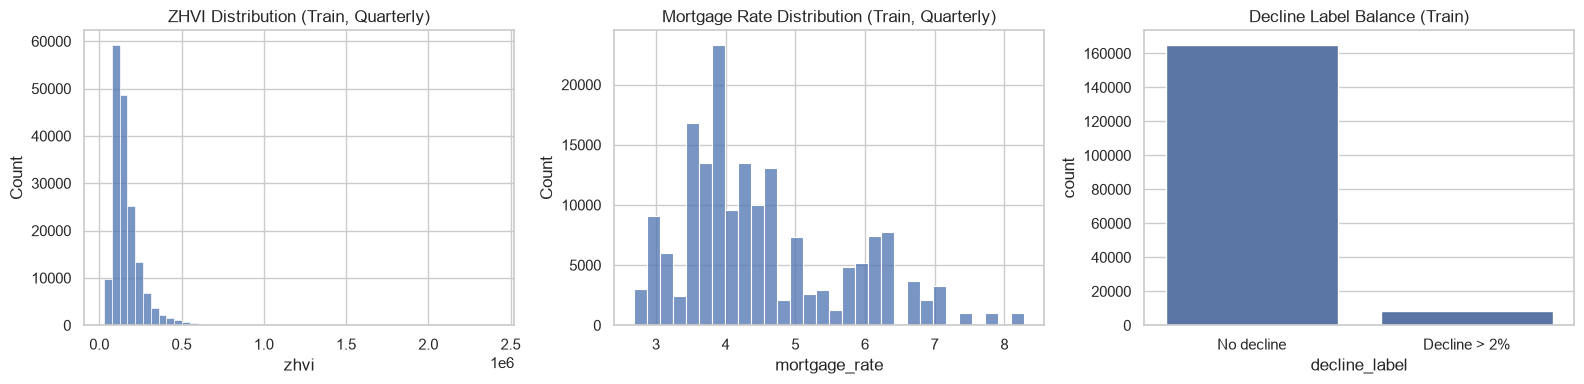

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(train_quarterly_labeled["zhvi"], bins=50, ax=axes[0])
axes[0].set_title("ZHVI Distribution (Train, Quarterly)")

sns.histplot(train_quarterly_labeled["mortgage_rate"], bins=30, ax=axes[1])
axes[1].set_title("Mortgage Rate Distribution (Train, Quarterly)")

sns.countplot(x="decline_label", data=train_quarterly_labeled, ax=axes[2])
axes[2].set_title("Decline Label Balance (Train)")
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["No decline", "Decline > 2%"])

plt.tight_layout()
os.makedirs("../outputs", exist_ok=True)
plt.savefig("../outputs/phase3_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

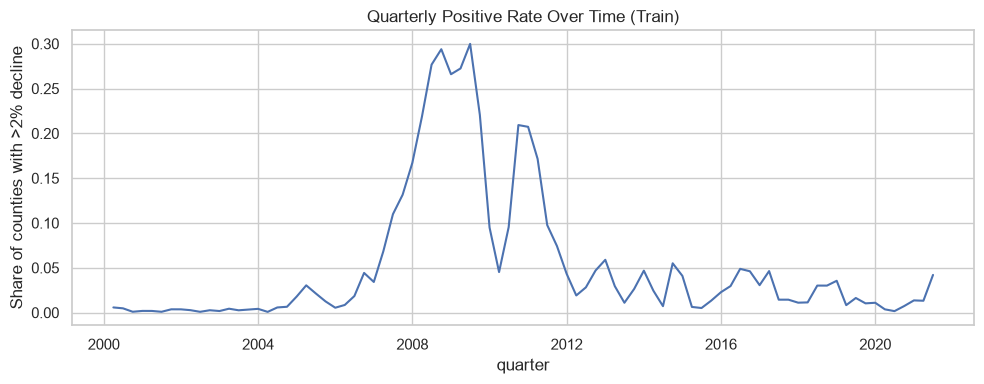

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
train_quarterly_labeled.groupby("quarter")["decline_label"].mean().plot(ax=ax)
ax.set_title("Quarterly Positive Rate Over Time (Train)")
ax.set_ylabel("Share of counties with >2% decline")
plt.tight_layout()
plt.savefig("../outputs/phase3_positive_rate_over_time.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Lag-Correlation Results

Reads back the `corr()` query — six correlations, one per candidate lag,
computed entirely server-side. No merge, no `.pct_change()`, no pandas
`.corr()` call: the number the notebook receives is already the answer.

In [6]:
def strip_leading_comments(s):
    lines = s.splitlines()
    while lines and lines[0].strip().startswith("--"):
        lines.pop(0)
    return "\n".join(lines).strip()

statements = [strip_leading_comments(s.strip()) for s in sql_text.split(";") if s.strip()]
statements = [s for s in statements if s]
corr_query = [s for s in statements if s.upper().startswith("SELECT")][-1]
corr_wide = pd.read_sql(corr_query, engine)

corr_df = (
    corr_wide.melt(var_name="lag_col", value_name="correlation_with_decline")
    .assign(lag_months=lambda d: d["lag_col"].str.extract(r"(\d+)").astype(int))
    [["lag_months", "correlation_with_decline"]]
    .sort_values("correlation_with_decline")
    .reset_index(drop=True)
)
corr_df

,lag_months,correlation_with_decline
0,12,-0.034213
1,9,-0.027653
2,6,-0.014557
3,3,-0.013343
4,1,-0.002408
5,2,0.003581


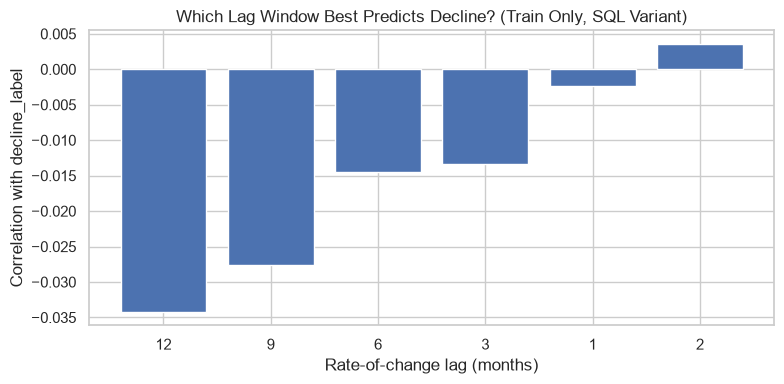

Strongest correlation: 12-month lag (r = -0.0342)


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(corr_df["lag_months"].astype(str), corr_df["correlation_with_decline"])
ax.set_xlabel("Rate-of-change lag (months)")
ax.set_ylabel("Correlation with decline_label")
ax.set_title("Which Lag Window Best Predicts Decline? (Train Only, SQL Variant)")
plt.tight_layout()
plt.savefig("../outputs/phase3_lag_correlation.png", dpi=200, bbox_inches="tight")
plt.show()

best_lag = corr_df.iloc[0]["lag_months"]
print(f"Strongest correlation: {best_lag:.0f}-month lag "
      f"(r = {corr_df.iloc[0]['correlation_with_decline']:.4f})")

In [8]:
with engine.connect() as conn:
    n_input = conn.execute(text("SELECT COUNT(*) FROM lag_correlation_input;")).scalar()
    n_labeled = conn.execute(text("SELECT COUNT(*) FROM train_quarterly_labeled;")).scalar()

print(f"train_quarterly_labeled rows: {n_labeled:,}")
print(f"lag_correlation_input rows:   {n_input:,}")
print(f"Rows lost in the join to quarter_end_rates: {n_labeled - n_input:,}")

train_quarterly_labeled rows: 173,824
lag_correlation_input rows:   173,824
Rows lost in the join to quarter_end_rates: 0


In [10]:
lag_input = pd.read_sql("SELECT * FROM lag_correlation_input;", engine)

roc_cols = ["roc_1m", "roc_2m", "roc_3m", "roc_6m", "roc_9m", "roc_12m"]
corr_cols = ["corr_1m", "corr_2m", "corr_3m", "corr_6m", "corr_9m", "corr_12m"]

pandas_corr = lag_input[roc_cols].corrwith(lag_input["decline_label"])

comparison = pd.DataFrame({
    "postgres_corr": corr_wide.iloc[0][corr_cols].values,
    "pandas_corr_same_data": pandas_corr.values,
}, index=roc_cols)
comparison["diff"] = comparison["postgres_corr"] - comparison["pandas_corr_same_data"]
comparison

,postgres_corr,pandas_corr_same_data,diff
roc_1m,-0.002408,-0.002408,1.131473e-15
roc_2m,0.003581,0.003581,4.443494e-15
roc_3m,-0.013343,-0.013343,2.548309e-15
roc_6m,-0.014557,-0.014557,1.991289e-14
roc_9m,-0.027653,-0.027653,-1.220898e-14
roc_12m,-0.034213,-0.034213,1.076916e-14


**Expected:** these six correlation values should match the pandas pipeline's
almost exactly (12-month lag strongest, r ≈ -0.039) — same underlying data and
same lag definitions, just computed by Postgres's `corr()` instead of pandas.
Small floating-point differences are possible depending on how each engine
handles the correlation formula internally; a difference beyond the 3rd–4th
decimal place would be worth investigating rather than assuming is rounding.

As before: this weak-correlation result (even the best lag barely clears
"noise level") is a finding about the *data*, not about which pipeline you
used — worth raising with the team either way before Phase 4 locks in a lag
choice.

## Status

Phase 3 (SQL variant) complete once the quarterly label matches the pandas
baseline (173,824 rows, 4.96%) and the correlation table above runs cleanly.